In [1]:
from typing import TypedDict, Optional
from langgraph.graph import StateGraph, START, END

In [ ]:
# 1. Define State
class BatsmanState(TypedDict):
    # Inputs
    batsman_name: str
    runs: int
    balls: int
    fours: int
    sixes: int

    # Computed Metrics
    strike_rate: Optional[float]
    boundary_percent: Optional[float]
    balls_per_boundary: Optional[float]

    # Final Aggregated Output
    summary: Optional[str]

In [ ]:
# 2. Define Parallel Calculation Nodes

# !! Since we are working with partial states in parallel, only return the updated part of the state in a dictionary

def calculate_strike_rate(state: BatsmanState) -> dict:

    runs = state["runs"]
    balls = state["balls"]
    sr = (runs / balls * 100) if balls > 0 else 0.0
    return {"strike_rate": round(sr, 2)}


def calculate_boundary_percent(state: BatsmanState) -> dict:
  
    runs = state["runs"]
    fours = state["fours"]
    sixes = state["sixes"]
    boundary_runs = (fours * 4) + (sixes * 6)
    bp = (boundary_runs / runs * 100) if runs > 0 else 0.0
    return {"boundary_percent": round(bp, 2)}


def calculate_balls_per_boundary(state: BatsmanState) -> dict:

    balls = state["balls"]
    total_boundaries = state["fours"] + state["sixes"]
    bpb = (balls / total_boundaries) if total_boundaries > 0 else 0.0
    return {"balls_per_boundary": round(bpb, 2)}

In [ ]:
# 3. Define Summary Node (Fan-In Aggregator)
def summary(state: BatsmanState) -> dict:

    report = (
        f"========================================\n"
        f"🏏 Performance Summary: {state.get('batsman_name', 'Batsman')}\n"
        f"========================================\n"
        f"• Runs: {state['runs']} off {state['balls']} balls\n"
        f"• Boundaries: {state['fours']} fours, {state['sixes']} sixes\n"
        f"• Strike Rate: {state['strike_rate']}\n"
        f"• Boundary Percentage: {state['boundary_percent']}%\n"
        f"• Balls Per Boundary: {state['balls_per_boundary']} balls\n"
        f"========================================"
    )
    return {"summary": report}

In [5]:
# 4. Build Parallel Graph
graph = StateGraph(BatsmanState)

# Add nodes
graph.add_node("calculate_strike_rate", calculate_strike_rate)
graph.add_node("calculate_boundary_percent", calculate_boundary_percent)
graph.add_node("calculate_balls_per_boundary", calculate_balls_per_boundary)
graph.add_node("summary", summary)

# Fan-Out: START triggers all 3 nodes in parallel
graph.add_edge(START, "calculate_strike_rate")
graph.add_edge(START, "calculate_boundary_percent")
graph.add_edge(START, "calculate_balls_per_boundary")

# Fan-In: All 3 parallel branches merge into summary
graph.add_edge("calculate_strike_rate", "summary")
graph.add_edge("calculate_boundary_percent", "summary")
graph.add_edge("calculate_balls_per_boundary", "summary")

# Summary connects to END
graph.add_edge("summary", END)

# Compile workflow
workflow = graph.compile()

In [6]:
# 5. Execute the Parallel Workflow
initial_input = {
    "batsman_name": "Virat Kohli",
    "runs": 82,
    "balls": 53,
    "fours": 6,
    "sixes": 4
}

final_state = workflow.invoke(initial_input)

# Print the full final state and the formatted summary
print(final_state["summary"])
print("\nRaw State:", final_state)

🏏 Performance Summary: Virat Kohli
• Runs: 82 off 53 balls
• Boundaries: 6 fours, 4 sixes
• Strike Rate: 154.72
• Boundary Percentage: 58.54%
• Balls Per Boundary: 5.3 balls

Raw State: {'batsman_name': 'Virat Kohli', 'runs': 82, 'balls': 53, 'fours': 6, 'sixes': 4, 'strike_rate': 154.72, 'boundary_percent': 58.54, 'balls_per_boundary': 5.3, 'summary': '========================================\n🏏 Performance Summary: Virat Kohli\n========================================\n• Runs: 82 off 53 balls\n• Boundaries: 6 fours, 4 sixes\n• Strike Rate: 154.72\n• Boundary Percentage: 58.54%\n• Balls Per Boundary: 5.3 balls\n========================================'}


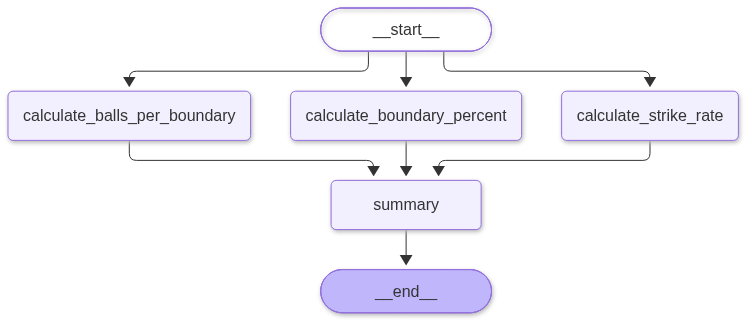

In [7]:
# 6. Visualize the Parallel Graph (Fan-Out -> Fan-In)
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())